# EDA

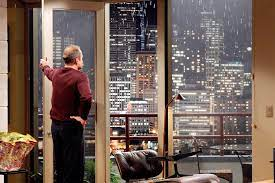

In [155]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import math 
import numpy as np
plt.rcParams.update(
    {"figure.figsize": (8, 5), "axes.facecolor": "white", "axes.edgecolor": "black"}
)
plt.rcParams["figure.facecolor"] = "w"
pd.plotting.register_matplotlib_converters()
pd.set_option("display.float_format", lambda x: "%.3f" % x)
# folder with your data
source = "/Users/tqd/neuefische-bootcamp/week3-EDA-project/data"
file_path = os.path.join(source, "eda.csv")
# load the raw data once
df_raw = pd.read_csv(file_path)

# Hypotheses

**Client:** Nicole Johnson

**Characteristics:** Looking for a mid-priced home in a lively, central neighborhood, planning to buy within the next year.

**Business question:** Where and when can the buyer find a mid-priced house in a lively, central area of King County?

**Hypothesis 1 (central):** The closer a house is to downtown Seattle, the higher its price. Mid-priced houses near the center will therefore be smaller or have a lower grade.

**Hypothesis 2 (timing):** Houses sold in winter are cheaper than houses sold in spring and summer, so the buyer gets more for their money by buying in winter.

**Hypothesis 3 (age):** Older houses near the center are cheaper than newer houses of similar size, so the buyer can afford a central home by choosing an older one.

# Explore
This is the time to explore the data, check for missing data, extreme values, outliers. Look at the usual suspects when you look at values: the appearance of groups, skewness, appearance of unexpected values, where are the data values centered and how widely are values separated. Do all this meet your expectations from your domain knowledge?

In [133]:
# checkout for missing data, extreme values, outliers
df_raw.head()
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 21597 entries, 0 to 21596
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21597 non-null  int64  
 1   bedrooms       21597 non-null  float64
 2   bathrooms      21597 non-null  float64
 3   sqft_living    21597 non-null  float64
 4   sqft_lot       21597 non-null  float64
 5   floors         21597 non-null  float64
 6   waterfront     19206 non-null  float64
 7   view           21534 non-null  float64
 8   condition      21597 non-null  int64  
 9   grade          21597 non-null  int64  
 10  sqft_above     21597 non-null  float64
 11  sqft_basement  21145 non-null  float64
 12  yr_built       21597 non-null  int64  
 13  yr_renovated   17749 non-null  float64
 14  zipcode        21597 non-null  int64  
 15  lat            21597 non-null  float64
 16  long           21597 non-null  float64
 17  sqft_living15  21597 non-null  float64
 18  sqft_lot15     21

In [156]:
#check the data
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
id,21597.000,4580474287.771,2876735715.748,1000102.000,2123049175.000,3904930410.000,7308900490.000,9900000190.000
bedrooms,21597.000,3.373,0.926,1.000,3.000,3.000,4.000,33.000
bathrooms,21597.000,2.116,0.769,0.500,1.750,2.250,2.500,8.000
sqft_living,21597.000,2080.322,918.106,370.000,1430.000,1910.000,2550.000,13540.000
sqft_lot,21597.000,15099.409,41412.637,520.000,5040.000,7618.000,10685.000,1651359.000
floors,21597.000,1.494,0.540,1.000,1.000,1.500,2.000,3.500
waterfront,19206.000,0.008,0.087,0.000,0.000,0.000,0.000,1.000
view,21534.000,0.234,0.766,0.000,0.000,0.000,0.000,4.000
condition,21597.000,3.410,0.651,1.000,3.000,3.000,4.000,5.000
grade,21597.000,7.658,1.173,3.000,7.000,7.000,8.000,13.000


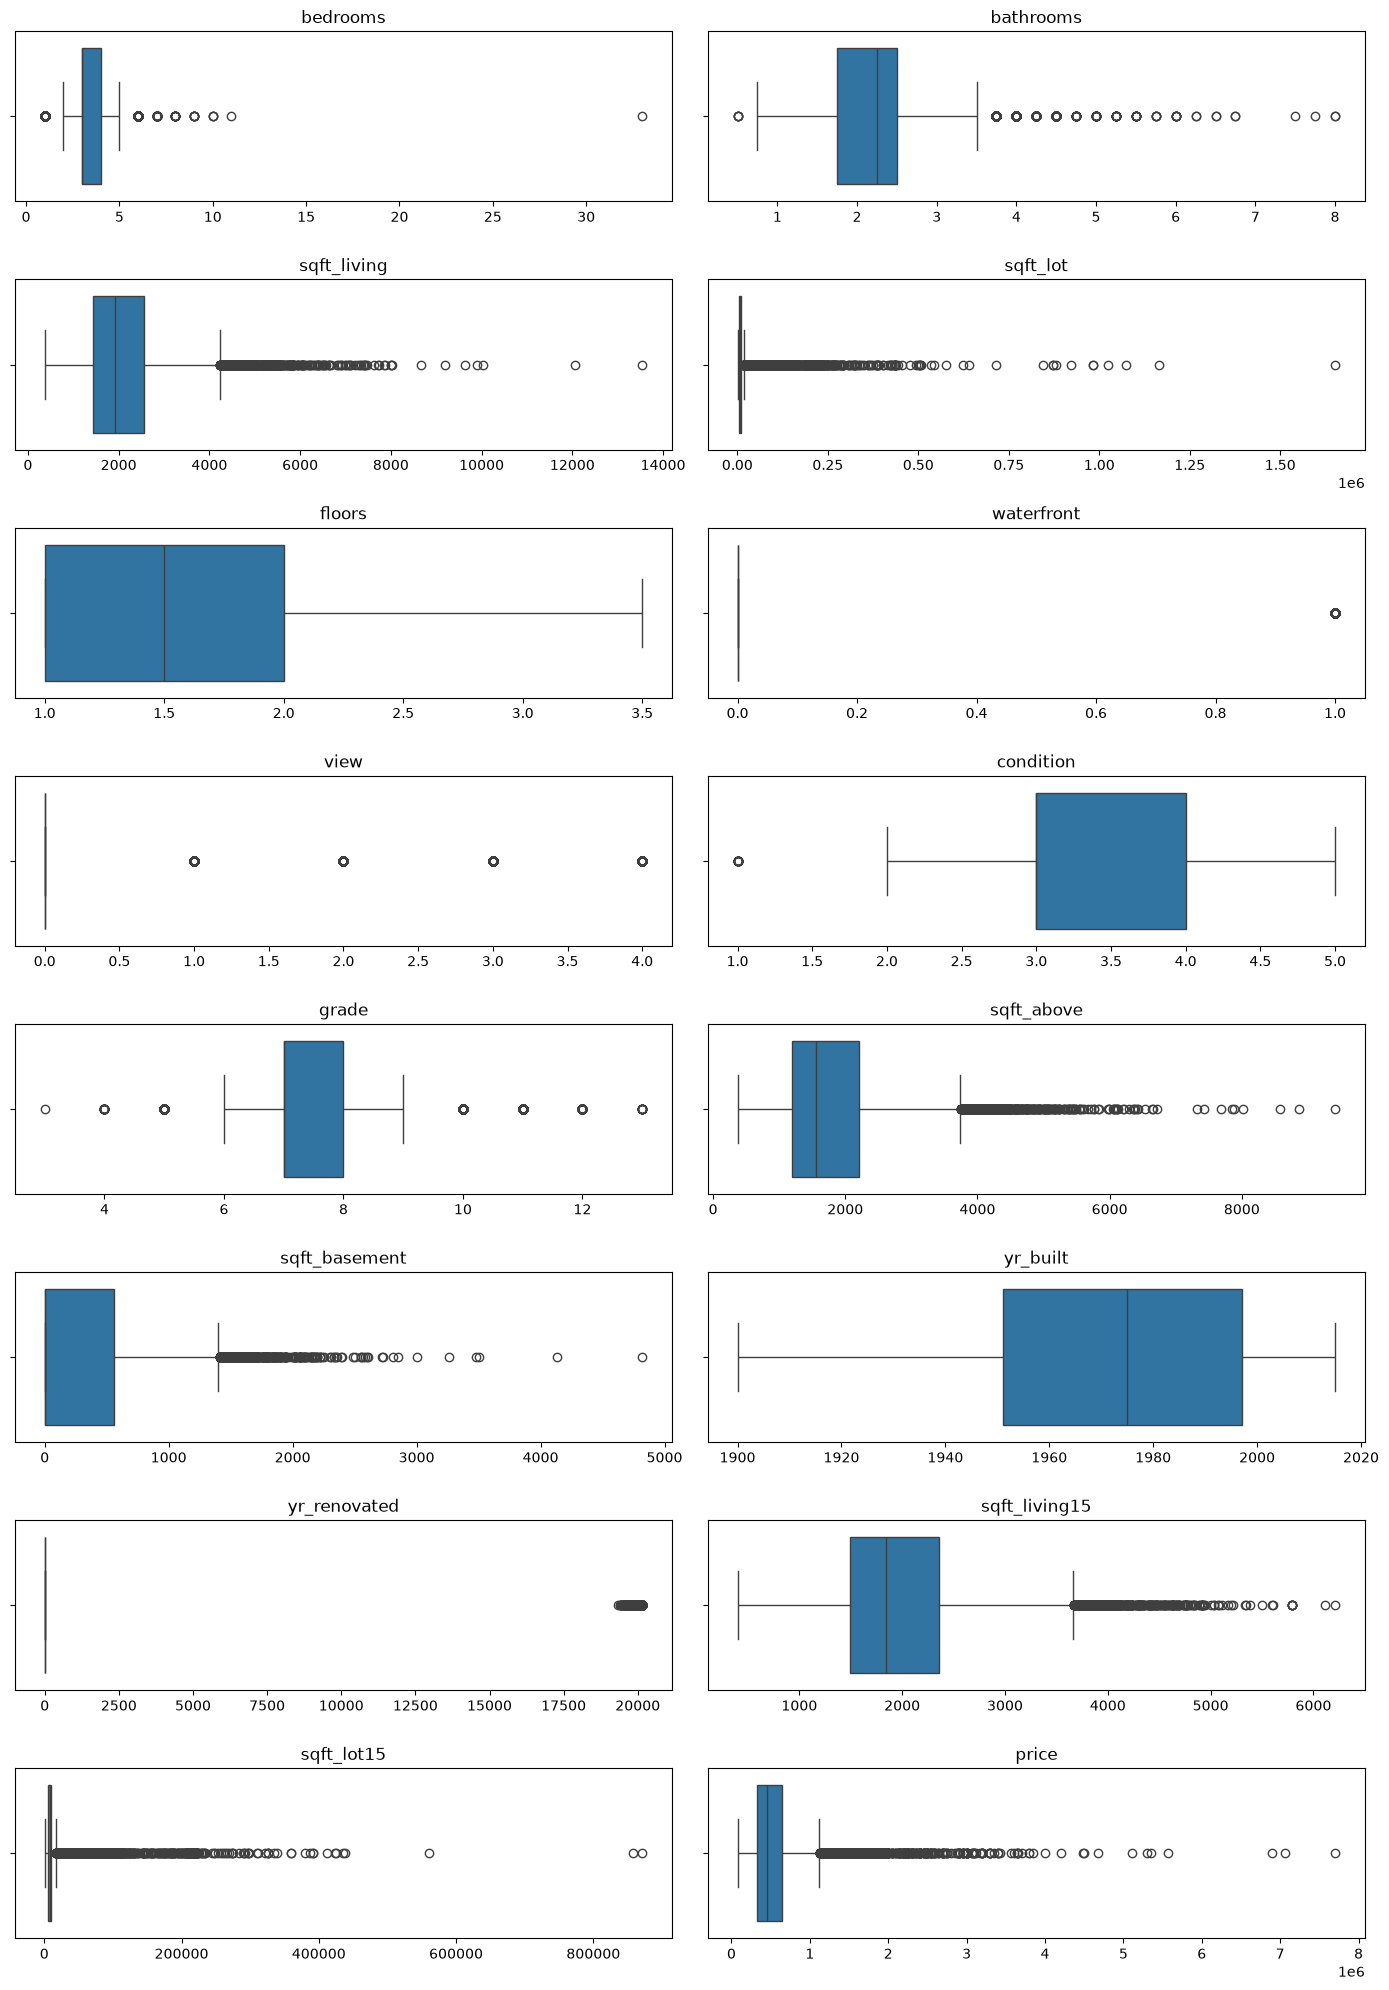

In [157]:
# check for extreme values and outliers

cols = df_raw.select_dtypes(include="number").columns.drop(["id", "zipcode", "lat", "long"])

n_cols = 2
n_rows = math.ceil(len(cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, n_rows * 2.5))
axes = axes.flatten()

for ax, col in zip(axes, cols):
    sns.boxplot(x=df_raw[col].dropna().astype(float), ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")

for ax in axes[len(cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [158]:
#check for missing values
missing_values = df_raw.isnull().sum()
print("Missing values:\n", missing_values[missing_values > 0])

Missing values:
 waterfront       2391
view               63
sqft_basement     452
yr_renovated     3848
dtype: int64


In [159]:
#clean the data
df = df_raw.copy()

# yr_renovated: fix x10 scaling; 0 and missing mean never renovated -> year built
df["yr_renovated"] = (df["yr_renovated"] / 10).astype("Int64").fillna(0)
df["yr_renovated"] = df["yr_renovated"].mask(df["yr_renovated"] == 0, df["yr_built"])

# bedrooms: fix the typo, then whole numbers
df.loc[df["bedrooms"] == 33, "bedrooms"] = 3
df["bedrooms"] = df["bedrooms"].astype(int)

# square footage: fill basement, then whole numbers
df["sqft_basement"] = df["sqft_basement"].fillna(df["sqft_living"] - df["sqft_above"])
sqft_cols = ["sqft_living", "sqft_lot", "sqft_above", "sqft_basement", "sqft_living15", "sqft_lot15"]
df[sqft_cols] = df[sqft_cols].astype(int)

# waterfront and view: missing means no waterfront / no special view
df["waterfront"] = df["waterfront"].fillna(0).astype(int)
df["view"] = df["view"].fillna(0).astype(int)

# zipcode as a label, date as a real date
df["zipcode"] = df["zipcode"].astype("category")
df["date"] = pd.to_datetime(df["date"])


In [161]:
# check the cleaned data
df.info()
df.isna().sum().sum()   # should be 0
df.head(10)

<class 'pandas.DataFrame'>
RangeIndex: 21597 entries, 0 to 21596
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id             21597 non-null  int64         
 1   bedrooms       21597 non-null  int64         
 2   bathrooms      21597 non-null  float64       
 3   sqft_living    21597 non-null  int64         
 4   sqft_lot       21597 non-null  int64         
 5   floors         21597 non-null  float64       
 6   waterfront     21597 non-null  int64         
 7   view           21597 non-null  int64         
 8   condition      21597 non-null  int64         
 9   grade          21597 non-null  int64         
 10  sqft_above     21597 non-null  int64         
 11  sqft_basement  21597 non-null  int64         
 12  yr_built       21597 non-null  int64         
 13  yr_renovated   21597 non-null  Int64         
 14  zipcode        21597 non-null  category      
 15  lat            21597 non-null 

,id,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,...,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,date,price
0,7129300520,3,1.000,1180,5650,1.000,0,0,3,7,...,0,1955,1955,98178,47.511,-122.257,1340,5650,2014-10-13,221900.000
1,6414100192,3,2.250,2570,7242,2.000,0,0,3,7,...,400,1951,1991,98125,47.721,-122.319,1690,7639,2014-12-09,538000.000
2,5631500400,2,1.000,770,10000,1.000,0,0,3,6,...,0,1933,1933,98028,47.738,-122.233,2720,8062,2015-02-25,180000.000
3,2487200875,4,3.000,1960,5000,1.000,0,0,5,7,...,910,1965,1965,98136,47.521,-122.393,1360,5000,2014-12-09,604000.000
4,1954400510,3,2.000,1680,8080,1.000,0,0,3,8,...,0,1987,1987,98074,47.617,-122.045,1800,7503,2015-02-18,510000.000
5,7237550310,4,4.500,5420,101930,1.000,0,0,3,11,...,1530,2001,2001,98053,47.656,-122.005,4760,101930,2014-05-12,1230000.000
6,1321400060,3,2.250,1715,6819,2.000,0,0,3,7,...,0,1995,1995,98003,47.310,-122.327,2238,6819,2014-06-27,257500.000
7,2008000270,3,1.500,1060,9711,1.000,0,0,3,7,...,0,1963,1963,98198,47.410,-122.315,1650,9711,2015-01-15,291850.000
8,2414600126,3,1.000,1780,7470,1.000,0,0,3,7,...,730,1960,1960,98146,47.512,-122.337,1780,8113,2015-04-15,229500.000
9,3793500160,3,2.500,1890,6560,2.000,0,0,3,7,...,0,2003,2003,98038,47.368,-122.031,2390,7570,2015-03-12,323000.000


# Check relationships 

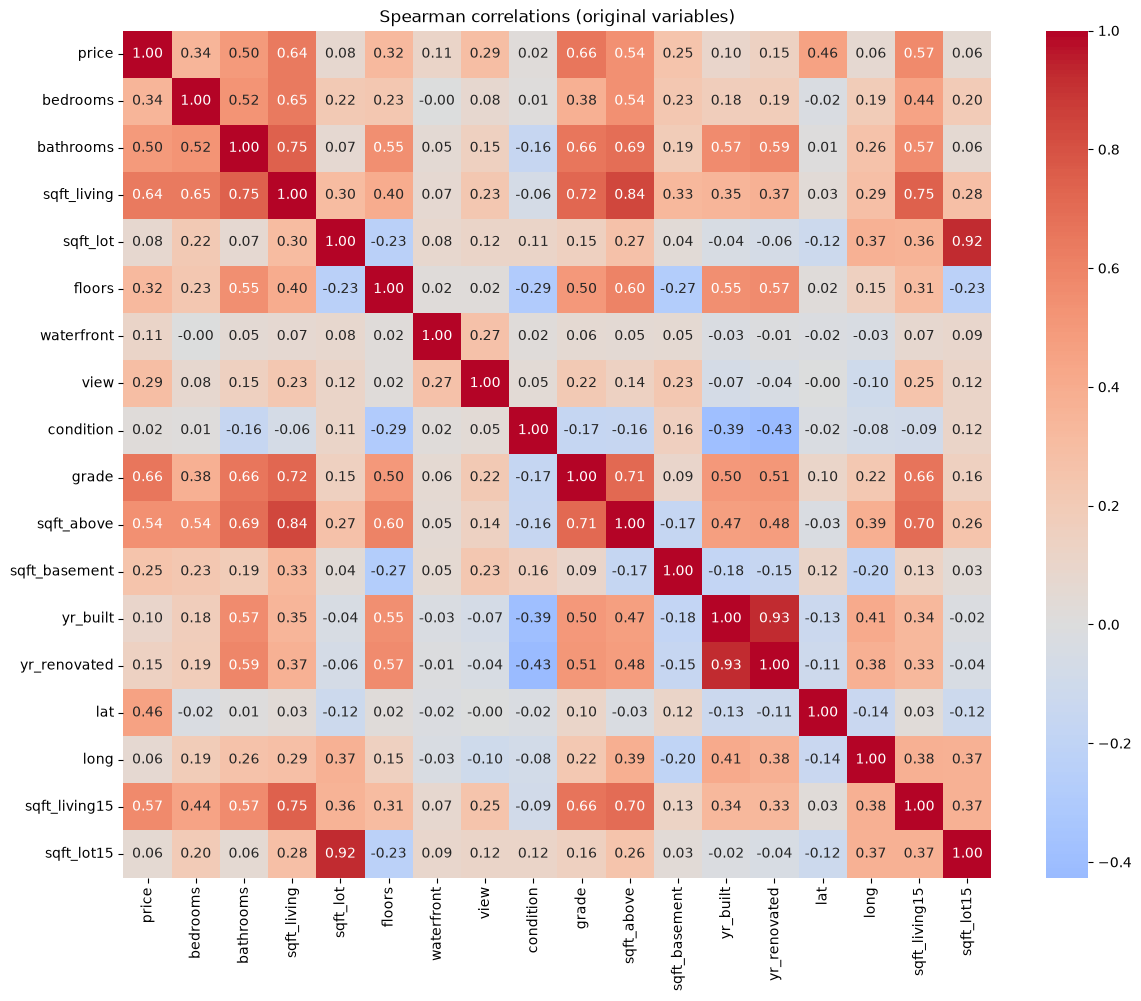

In [162]:
#calculate the correlation matrix
num_cols = ["price", "bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors",
            "waterfront", "view", "condition", "grade", "sqft_above", "sqft_basement",
            "yr_built", "yr_renovated", "lat", "long", "sqft_living15", "sqft_lot15"]

corr = df[num_cols].corr(method="spearman")

plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman correlations (original variables)")
plt.show()

In [163]:
#to see the correlation of all variables with price
corr["price"].drop("price").sort_values(ascending=False)

grade           0.658
sqft_living     0.644
sqft_living15   0.572
sqft_above      0.542
bathrooms       0.497
lat             0.456
bedrooms        0.344
floors          0.322
view            0.293
sqft_basement   0.251
yr_renovated    0.145
waterfront      0.111
yr_built        0.102
sqft_lot        0.075
long            0.064
sqft_lot15      0.063
condition       0.018
Name: price, dtype: float64

# Testing hypotheis 3: 
*the prices are not correlated to the year built and year renovated *

In [166]:
# --- new columns for the hypotheses ---
downtown_lat, downtown_long = 47.6062, -122.3321
df["dist_km"] = np.sqrt(
    ((df["lat"] - downtown_lat) * 111) ** 2 +
    ((df["long"] - downtown_long) * 111 * np.cos(np.radians(downtown_lat))) ** 2
)
df["month"] = df["date"].dt.month
df["sale_year"] = df["date"].dt.year
df["age"] = (df["sale_year"] - df["yr_built"]).clip(lower=0)
df["age_since_work"] = (df["sale_year"] - df["yr_renovated"]).clip(lower=0)
df["price_per_sqft"] = df["price"] / df["sqft_living"]
df["price_per_sqft"].describe

<bound method Series.describe of 0       188.051
1       209.339
2       233.766
3       308.163
4       303.571
          ...  
21592   235.294
21593   173.160
21594   394.217
21595   250.000
21596   318.627
Name: price_per_sqft, Length: 21597, dtype: float64>

In [171]:
fig = px.scatter_map(
    df, lat="lat", lon="long", color="price_per_sqft",
    color_continuous_scale="Viridis",
    range_color=[df["price_per_sqft"].quantile(0.05), df["price_per_sqft"].quantile(0.95)],
    hover_data={"price": ":,.0f", "price_per_sqft": ":,.0f", "sqft_living": ":,.0f",
                "yr_built": True, "zipcode": True},
    center={"lat": 47.5, "lon": -122.2},
    zoom=9, height=700, opacity=0.6,
    title="Price per square foot (USD/sqft)"
)
fig.update_layout(map_style="open-street-map")
fig.show()


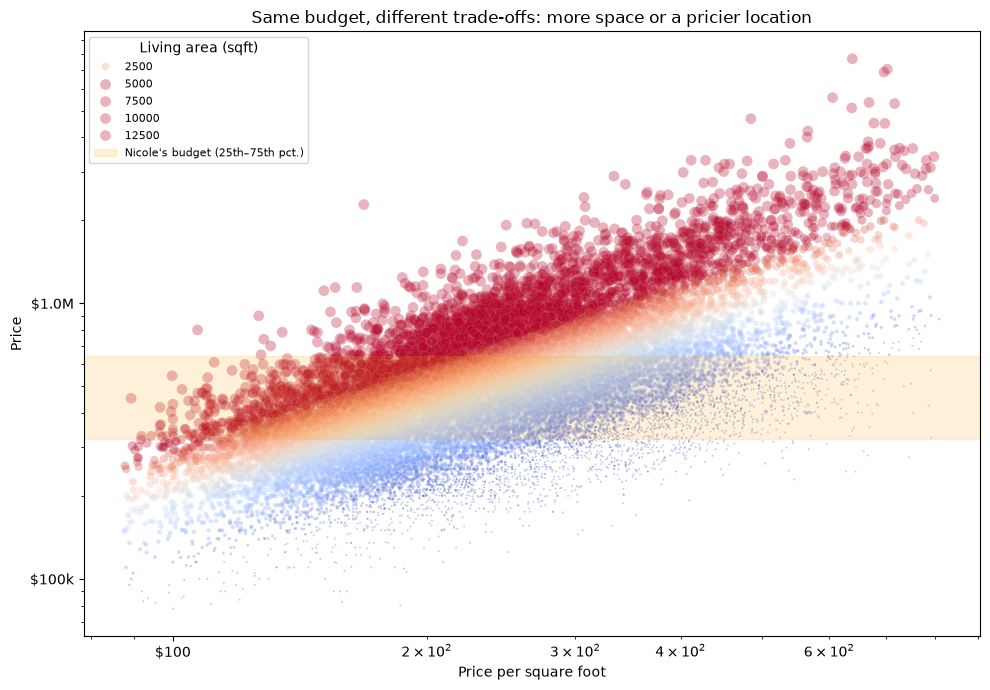

In [175]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Nicole's budget: middle price range
low, high = df["price"].quantile([0.25, 0.75])

fig, ax = plt.subplots(figsize=(10, 7))

sns.scatterplot(data=df, x="price_per_sqft", y="price",
                hue="sqft_living", hue_norm=(1000, 3000), palette="coolwarm",
                size="sqft_living", sizes=(2, 60), size_norm=(1000, 4000),
                alpha=0.3, ax=ax)

# log scales with readable labels
ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(
    lambda y, _: f"${y/1e6:.1f}M" if y >= 1e6 else f"${y/1e3:.0f}k"))

# highlight Nicole's budget
ax.axhspan(low, high, color="orange", alpha=0.15, label="Nicole's budget (25th–75th pct.)")

ax.set_xlabel("Price per square foot")
ax.set_ylabel("Price")
ax.set_title("Same budget, different trade-offs: more space or a pricier location")
ax.legend(title="Living area (sqft)", loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()

In [176]:
low, high = df["price"].quantile([0.25, 0.75])
df_mid = df[df["price"].between(low, high)].copy()

# top 25% price per sqft within her budget
ppsf_cut = df_mid["price_per_sqft"].quantile(0.75)
df_mid["high_ppsf"] = df_mid["price_per_sqft"] >= ppsf_cut

print(f"Budget: ${low:,.0f} – ${high:,.0f}")
print(f"High price per sqft: ${ppsf_cut:,.0f} or more")
print(df_mid["high_ppsf"].value_counts())

Budget: $322,000 – $645,000
High price per sqft: $315 or more
high_ppsf
False    8123
True     2709
Name: count, dtype: int64


In [177]:
by_zip = (df_mid.groupby("zipcode", observed=True)
                .agg(median_ppsf=("price_per_sqft", "median"),
                     median_price=("price", "median"),
                     median_sqft=("sqft_living", "median"),
                     median_dist_km=("dist_km", "median"),
                     n_sales=("id", "count"))
                .query("n_sales >= 20")
                .sort_values("median_ppsf", ascending=False))

by_zip.head(10)

,median_ppsf,median_price,median_sqft,median_dist_km,n_sales
zipcode,,,,,
98109,421.739,550000.000,1180.000,3.694,31
98102,400.641,527500.000,1350.000,3.371,39
98112,389.431,529000.000,1360.000,3.154,57
98105,387.879,542000.000,1370.000,7.171,99
98119,380.333,572750.000,1400.000,4.772,68
98107,372.868,503000.000,1360.000,8.056,207
98117,350.299,495000.000,1410.000,9.672,383
98199,349.180,517500.000,1470.000,6.669,139
98103,348.837,485000.000,1380.000,8.739,381


In [178]:
import plotly.express as px

fig = px.scatter_map(
    df_mid, lat="lat", lon="long", color="price_per_sqft",
    color_continuous_scale="Viridis",
    range_color=[df_mid["price_per_sqft"].quantile(0.05), df_mid["price_per_sqft"].quantile(0.95)],
    hover_data={"price": ":,.0f", "price_per_sqft": ":,.0f", "sqft_living": ":,.0f",
                "zipcode": True, "dist_km": ":.1f"},
    center={"lat": 47.5, "lon": -122.2},
    zoom=9, height=700, opacity=0.6,
    title="Price per sqft within Nicole's budget"
)
fig.update_layout(map_style="open-street-map")
fig.show()

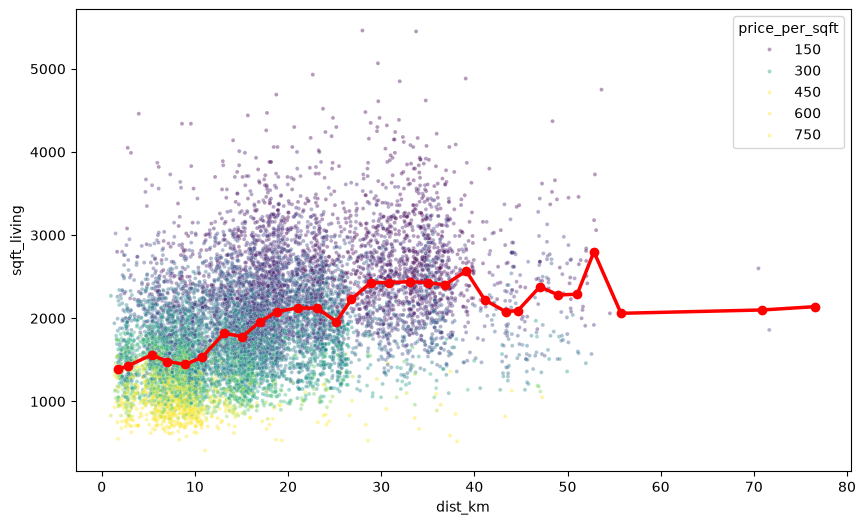

In [180]:
# Nicole's budget: middle price range
low, high = df["price"].quantile([0.25, 0.75])
df_mid = df[df["price"].between(low, high)].copy()

fig, ax = plt.subplots(figsize=(10, 6))

# each house, colored by price per sqft
sns.scatterplot(data=df_mid, x="dist_km", y="sqft_living", hue="price_per_sqft",
                hue_norm=(df_mid["price_per_sqft"].quantile(0.05), df_mid["price_per_sqft"].quantile(0.95)),
                palette="viridis", alpha=0.4, s=8, ax=ax)

# median living area per 2 km distance band
bins = np.arange(0, df_mid["dist_km"].max() + 2, 2)
df_mid["dist_band"] = pd.cut(df_mid["dist_km"], bins=bins)
trend = df_mid.groupby("dist_band", observed=True).agg(
    dist=("dist_km", "median"), sqft=("sqft_living", "median"))
ax.plot(trend["dist"], trend["sqft"], color="red", linewidth=2.5, marker="o", label="Median living area")

# note that only Nicole's budget

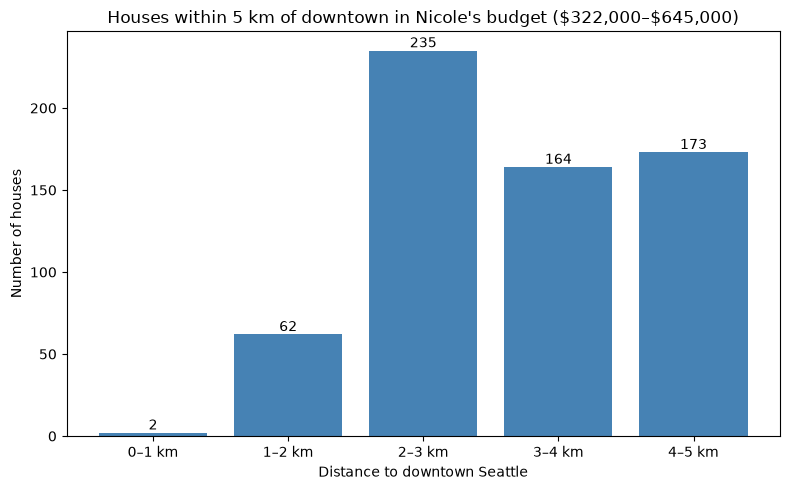

Total within 5 km: 636 houses


In [181]:


# Nicole's budget
low, high = df["price"].quantile([0.25, 0.75])
df_mid = df[df["price"].between(low, high)].copy()

# houses within 5 km, grouped into 1 km bands
central = df_mid[df_mid["dist_km"] <= 5].copy()
central["dist_band"] = pd.cut(central["dist_km"], bins=[0, 1, 2, 3, 4, 5],
                              labels=["0–1 km", "1–2 km", "2–3 km", "3–4 km", "4–5 km"])
counts = central["dist_band"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(counts.index, counts.values, color="steelblue")
ax.bar_label(bars)   # show the number on top of each bar

ax.set_xlabel("Distance to downtown Seattle")
ax.set_ylabel("Number of houses")
ax.set_title(f"Houses within 5 km of downtown in Nicole's budget (\\${low:,.0f}–\\${high:,.0f})")

plt.tight_layout()
plt.show()

print(f"Total within 5 km: {len(central)} houses")

Houses in this subset: 636
sqft_living      0.420
sqft_living15    0.331
lat              0.324
grade            0.300
bathrooms        0.212
bedrooms         0.202
view             0.164
condition        0.150
sqft_lot         0.117
long            -0.116
sqft_basement    0.116
yr_built        -0.097
floors           0.079
yr_renovated    -0.073
sqft_lot15       0.072
waterfront         NaN
Name: price, dtype: float64


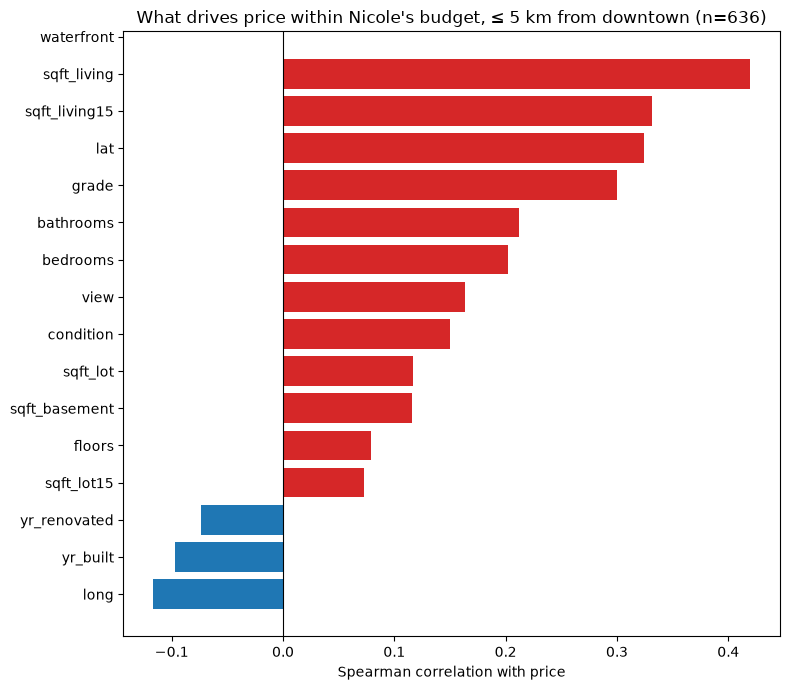

In [189]:


cols = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors", "waterfront", "view",
        "condition", "grade", "sqft_basement", "yr_built", "yr_renovated",
        "lat", "long", "sqft_living15", "sqft_lot15"]

# Nicole's budget and within 5 km of downtown
low, high = df["price"].quantile([0.25, 0.75])
nicole = df[df["price"].between(low, high) & (df["dist_km"] <= 5)]
print(f"Houses in this subset: {len(nicole)}")

# correlation with price, sorted by strength
corr_price = nicole[cols + ["price"]].corr(method="spearman")["price"].drop("price")
print(corr_price.sort_values(key=abs, ascending=False))

# bar chart
corr_sorted = corr_price.sort_values()
plt.figure(figsize=(8, 7))
plt.barh(corr_sorted.index, corr_sorted.values,
         color=["tab:red" if v > 0 else "tab:blue" for v in corr_sorted])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Spearman correlation with price")
plt.title(f"What drives price within Nicole's budget, ≤ 5 km from downtown (n={len(nicole)})")
plt.tight_layout()
plt.show()

In [187]:
import matplotlib.pyplot as plt

# Nicole's budget
low, high = df["price"].quantile([0.25, 0.75])
df_mid = df[df["price"].between(low, high) & (df["dist_km"] <= 5)].copy()

# compare zip codes
by_zip = (df_mid.groupby("zipcode", observed=True)
                .agg(median_ppsf=("price_per_sqft", "median"),
                     median_price=("price", "median"),
                     median_sqft=("sqft_living", "median"),
                     median_dist_km=("dist_km", "median"),
                     n_sales=("id", "count"))
                .query("n_sales >= 20")
                .sort_values("median_ppsf", ascending=False))

by_zip.head(15)

,median_ppsf,median_price,median_sqft,median_dist_km,n_sales
zipcode,,,,,
98119,446.939,575000.000,1220.000,4.431,39
98109,421.739,550000.000,1180.000,3.694,31
98102,402.875,528750.000,1360.000,3.366,38
98112,389.431,529000.000,1360.000,3.154,57
98122,339.715,499500.000,1485.000,2.365,178
98116,333.333,543750.000,1665.000,4.551,30
98144,292.373,420000.000,1520.000,3.139,213


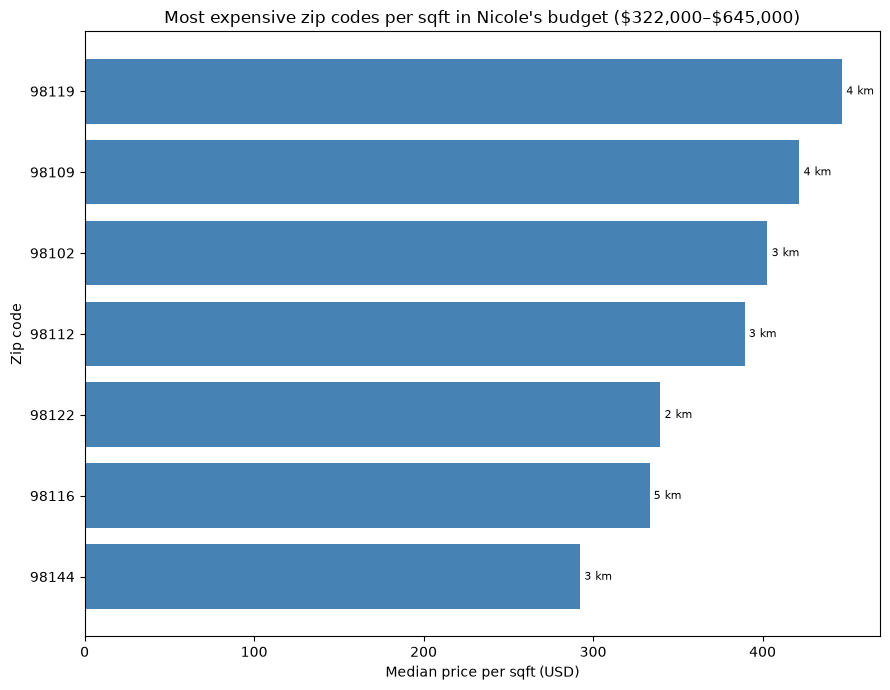

In [188]:
top = by_zip.head(15).sort_values("median_ppsf")

fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(top.index.astype(str), top["median_ppsf"], color="steelblue")
ax.bar_label(bars, labels=[f"{d:.0f} km" for d in top["median_dist_km"]], padding=3, fontsize=8)

ax.set_xlabel("Median price per sqft (USD)")
ax.set_ylabel("Zip code")
ax.set_title(f"Most expensive zip codes per sqft in Nicole's budget (\\${low:,.0f}–\\${high:,.0f})")
plt.tight_layout()
plt.show()

In [194]:
import plotly.express as px

# Nicole's budget, within 5 km of downtown
low, high = df["price"].quantile([0.25, 0.75])
df_mid = df[df["price"].between(low, high) & (df["dist_km"] <= 5)].copy()

# one row per zip code: its center and key numbers
zip_map = (df_mid.groupby("zipcode", observed=True)
                 .agg(lat=("lat", "median"),
                      long=("long", "median"),
                      median_ppsf=("price_per_sqft", "median"),
                      median_sqft=("sqft_living", "median"),
                      n_sales=("id", "count"))
                 .reset_index())
zip_map["zipcode"] = zip_map["zipcode"].astype(str)

fig = px.scatter_map(
    zip_map, lat="lat", lon="long",
    color="median_ppsf", size="n_sales", text="zipcode",
    color_continuous_scale="Viridis", size_max=40,
    hover_data={"median_ppsf": ":,.0f", "median_sqft": ":,.0f", "n_sales": True,
            "lat": False, "long": False, "zipcode": False},
    center={"lat": 47.61, "lon": -122.32}, zoom=11.5, height=700,
    title="Zip codes within 5 km of downtown, Nicole's budget"
)
fig.update_traces(textposition="top center")
fig.update_layout(map_style="open-street-map")

# mark downtown
fig.add_scattermap(lat=[47.6062], lon=[-122.3321], mode="markers+text",
                   marker={"size": 14, "color": "red"}, text=["Downtown"],
                   textposition="bottom center", name="Downtown")
fig.update_layout(
    coloraxis_colorbar=dict(title="Price/sqft (USD)"),
    legend=dict(x=0.01, y=0.99, bgcolor="rgba(255,255,255,0.8)")
)
fig.show()

Correlation with distance (Spearman):
price            -0.353
price_per_sqft   -0.622
Name: dist_km, dtype: float64 

All houses by distance band (km):
           median_price  median_ppsf  n_sales
dist_band                                    
0–5          638000.000      369.000     1348
5–10         536500.000      339.000     4289
10–20        453500.000      253.000     7752
20–30        455900.000      218.000     4462
30–50        312620.000      168.000     3549 

Nicole's budget ($322,000–$645,000) by distance band (km):
           median_sqft  median_grade  mean_grade  n_sales
dist_band                                                
0–5           1470.000         7.000       7.400      636
5–10          1470.000         7.000       7.200     2357
10–20         1850.000         7.000       7.400     4176
20–30         2140.000         8.000       7.800     2131
30–50         2415.000         8.000       7.900     1488


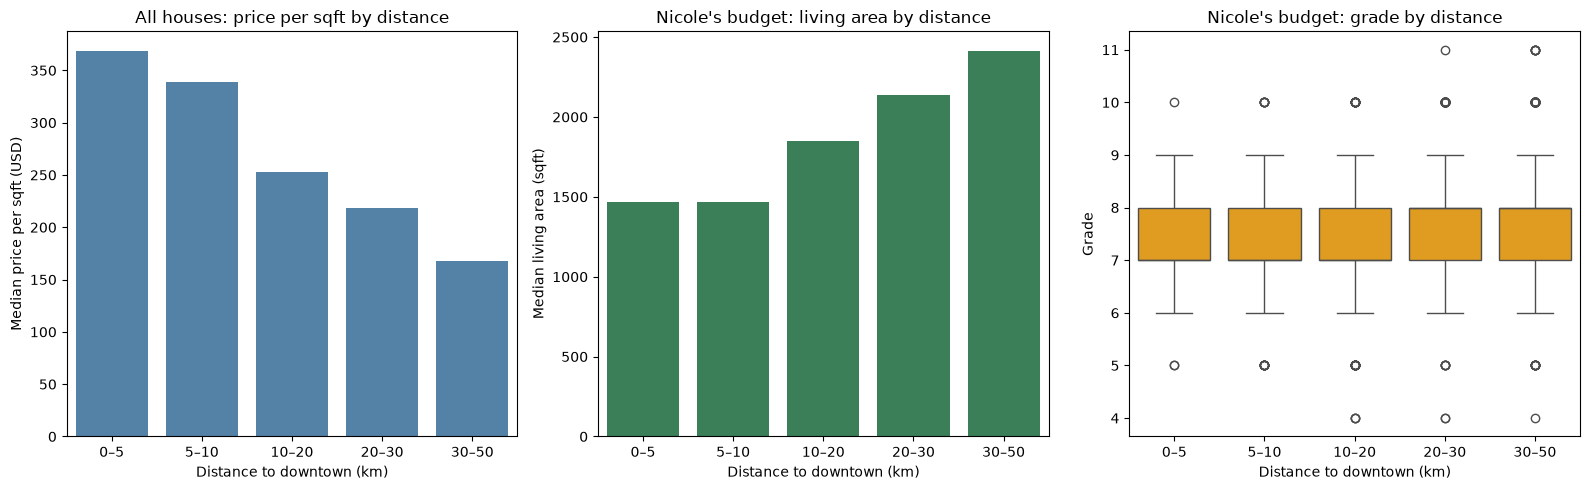

In [195]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- setup ---
downtown_lat, downtown_long = 47.6062, -122.3321
df["dist_km"] = np.sqrt(
    ((df["lat"] - downtown_lat) * 111) ** 2 +
    ((df["long"] - downtown_long) * 111 * np.cos(np.radians(downtown_lat))) ** 2
)
df["price_per_sqft"] = df["price"] / df["sqft_living"]

bands = [0, 5, 10, 20, 30, 50]
labels = ["0–5", "5–10", "10–20", "20–30", "30–50"]
df["dist_band"] = pd.cut(df["dist_km"], bins=bands, labels=labels)

low, high = df["price"].quantile([0.25, 0.75])
df_mid = df[df["price"].between(low, high)].copy()

# --- Part 1: closer to downtown = higher price? (all houses) ---
print("Correlation with distance (Spearman):")
print(df[["dist_km", "price", "price_per_sqft"]].corr(method="spearman")["dist_km"].drop("dist_km"), "\n")

part1 = df.groupby("dist_band", observed=True).agg(
    median_price=("price", "median"),
    median_ppsf=("price_per_sqft", "median"),
    n_sales=("id", "count"))
print("All houses by distance band (km):")
print(part1.round(0), "\n")

# --- Part 2: mid-priced houses near the center smaller or lower grade? ---
part2 = df_mid.groupby("dist_band", observed=True).agg(
    median_sqft=("sqft_living", "median"),
    median_grade=("grade", "median"),
    mean_grade=("grade", "mean"),
    n_sales=("id", "count"))
print(f"Nicole's budget (${low:,.0f}–${high:,.0f}) by distance band (km):")
print(part2.round(1))

# --- plots ---
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.barplot(x=part1.index, y=part1["median_ppsf"], color="steelblue", ax=axes[0])
axes[0].set_title("All houses: price per sqft by distance")
axes[0].set_xlabel("Distance to downtown (km)")
axes[0].set_ylabel("Median price per sqft (USD)")

sns.barplot(x=part2.index, y=part2["median_sqft"], color="seagreen", ax=axes[1])
axes[1].set_title("Nicole's budget: living area by distance")
axes[1].set_xlabel("Distance to downtown (km)")
axes[1].set_ylabel("Median living area (sqft)")

sns.boxplot(data=df_mid, x="dist_band", y="grade", color="orange", ax=axes[2])
axes[2].set_title("Nicole's budget: grade by distance")
axes[2].set_xlabel("Distance to downtown (km)")
axes[2].set_ylabel("Grade")

plt.tight_layout()
plt.show()

**Hypothesis 1 (central):** The closer a house is to downtown Seattle, the higher its price. Mid-priced houses near the center will therefore be smaller or have a lower grade.

**Result: partly supported.**

- Being central is expensive: the median price per square foot falls from about \$370 within 5 km of downtown to about \$170 at 30–50 km.
- Within Nicole's budget, central houses are smaller: about 1,470 sqft within 10 km, compared with about 2,400 sqft at 30–50 km.
- Central houses are **not** lower quality: the grade is the same (mostly 7–8) at every distance.

**Takeaway for Nicole:** Living centrally costs her space, not quality. Within 10 km she can expect a house of about 1,500 sqft of similar build quality to houses farther out.

All houses by season:
        median_price  median_ppsf  median_sqft  n_sales
season                                                 
Spring    465000.000      253.000     1900.000     6518
Summer    455000.000      246.000     1960.000     6328
Autumn    443725.000      242.000     1900.000     5056
Winter    430000.000      235.000     1880.000     3695 

Winter vs. spring/summer, price per sqft: -5.6%

Nicole's budget ($322,000–$645,000) by season:
        median_sqft  median_ppsf  median_grade  n_sales
season                                                 
Spring     1820.000      256.100         7.000     3297
Summer     1890.000      247.800         7.000     3153
Autumn     1870.000      247.800         7.000     2529
Winter     1870.000      243.300         7.000     1853


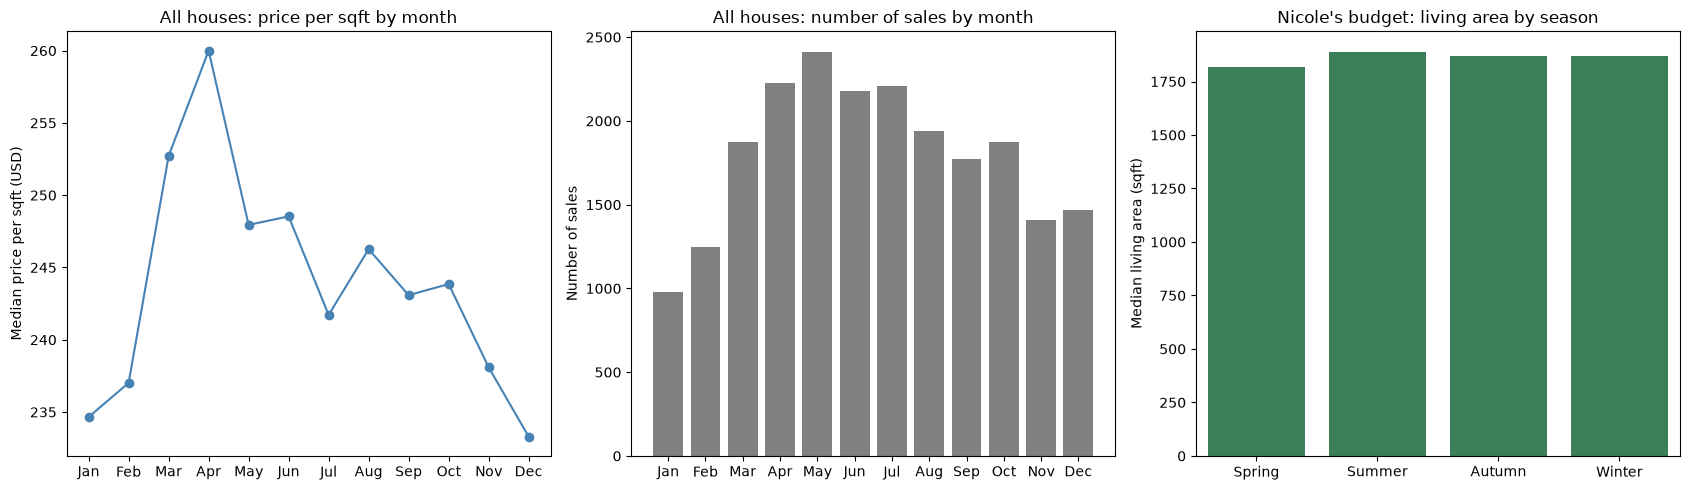

In [201]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- setup ---
df["date"] = pd.to_datetime(df["date"])
df["month"] = df["date"].dt.month
df["season"] = df["month"].map({12: "Winter", 1: "Winter", 2: "Winter",
                                3: "Spring", 4: "Spring", 5: "Spring",
                                6: "Summer", 7: "Summer", 8: "Summer",
                                9: "Autumn", 10: "Autumn", 11: "Autumn"})
df["price_per_sqft"] = df["price"] / df["sqft_living"]
season_order = ["Spring", "Summer", "Autumn", "Winter"]

low, high = df["price"].quantile([0.25, 0.75])
df_mid = df[df["price"].between(low, high)].copy()

# --- Part 1: are prices lower in winter? (all houses) ---
by_season = df.groupby("season").agg(
    median_price=("price", "median"),
    median_ppsf=("price_per_sqft", "median"),
    median_sqft=("sqft_living", "median"),
    n_sales=("id", "count")).loc[season_order]
print("All houses by season:")
print(by_season.round(0), "\n")

winter = by_season.loc["Winter", "median_ppsf"]
spring_summer = df[df["season"].isin(["Spring", "Summer"])]["price_per_sqft"].median()
print(f"Winter vs. spring/summer, price per sqft: {(winter / spring_summer - 1) * 100:+.1f}%\n")

# --- Part 2: does Nicole get more for her money in winter? ---
mid_by_season = df_mid.groupby("season").agg(
    median_sqft=("sqft_living", "median"),
    median_ppsf=("price_per_sqft", "median"),
    median_grade=("grade", "median"),
    n_sales=("id", "count")).loc[season_order]
print(f"Nicole's budget (${low:,.0f}–${high:,.0f}) by season:")
print(mid_by_season.round(1))

# --- plots ---
by_month = df.groupby("month").agg(median_ppsf=("price_per_sqft", "median"),
                                   n_sales=("id", "count"))
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].plot(month_names, by_month["median_ppsf"], marker="o", color="steelblue")
axes[0].set_title("All houses: price per sqft by month")
axes[0].set_ylabel("Median price per sqft (USD)")

axes[1].bar(month_names, by_month["n_sales"], color="gray")
axes[1].set_title("All houses: number of sales by month")
axes[1].set_ylabel("Number of sales")

sns.barplot(x=mid_by_season.index, y=mid_by_season["median_sqft"], color="seagreen", ax=axes[2])
axes[2].set_title("Nicole's budget: living area by season")
axes[2].set_xlabel("")
axes[2].set_ylabel("Median living area (sqft)")

plt.tight_layout()
plt.show()

Sales per month within 5 km:
month
1      52
2      76
3      97
4     142
5     162
6     153
7     153
8      96
9     121
10    120
11     95
12     81 

Houses within 5 km by season:
        median_price  median_ppsf  median_sqft  n_sales
season                                                 
Spring    640000.000      374.000     1790.000      401
Summer    640000.000      366.000     1795.000      402
Autumn    633000.000      358.000     1860.000      336
Winter    635000.000      372.000     1860.000      209 

Winter vs. spring/summer, price per sqft: +0.4%

Nicole's budget ($322,000–$645,000) within 5 km by season:
        median_sqft  median_ppsf  median_grade  n_sales
season                                                 
Spring     1390.000      340.200         7.000      190
Summer     1430.000      332.000         7.000      189
Autumn     1520.000      323.900         7.000      156
Winter     1510.000      325.400         7.000      101


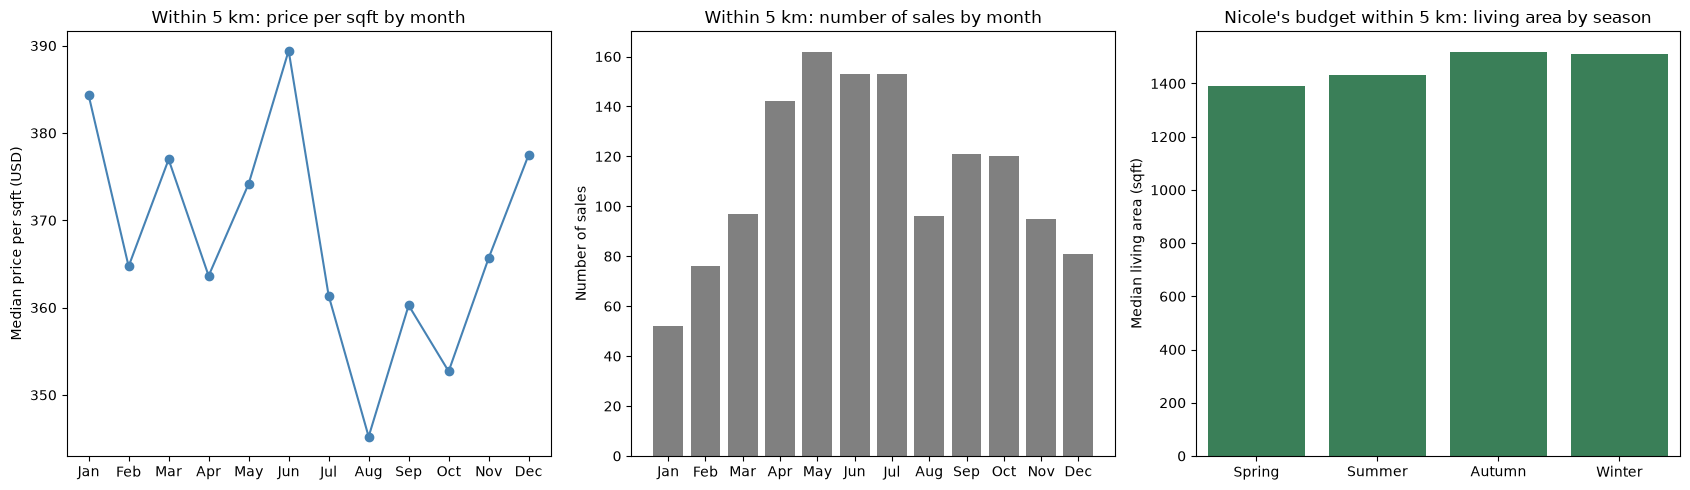

In [200]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- setup ---
df["date"] = pd.to_datetime(df["date"])
df["month"] = df["date"].dt.month
df["season"] = df["month"].map({12: "Winter", 1: "Winter", 2: "Winter",
                                3: "Spring", 4: "Spring", 5: "Spring",
                                6: "Summer", 7: "Summer", 8: "Summer",
                                9: "Autumn", 10: "Autumn", 11: "Autumn"})
df["price_per_sqft"] = df["price"] / df["sqft_living"]
season_order = ["Spring", "Summer", "Autumn", "Winter"]

# Nicole's budget from all houses, then filter by distance
low, high = df["price"].quantile([0.25, 0.75])
max_dist = 5   # km from downtown
df_central = df[df["dist_km"] <= max_dist].copy()
df_mid = df_central[df_central["price"].between(low, high)].copy()

print("Sales per month within", max_dist, "km:")
print(df_central.groupby("month")["id"].count().to_string(), "\n")

# --- Part 1: are prices lower in winter? (central houses) ---
by_season = df_central.groupby("season").agg(
    median_price=("price", "median"),
    median_ppsf=("price_per_sqft", "median"),
    median_sqft=("sqft_living", "median"),
    n_sales=("id", "count")).loc[season_order]
print(f"Houses within {max_dist} km by season:")
print(by_season.round(0), "\n")

winter = by_season.loc["Winter", "median_ppsf"]
spring_summer = df_central[df_central["season"].isin(["Spring", "Summer"])]["price_per_sqft"].median()
print(f"Winter vs. spring/summer, price per sqft: {(winter / spring_summer - 1) * 100:+.1f}%\n")

# --- Part 2: does Nicole get more for her money in winter? ---
mid_by_season = df_mid.groupby("season").agg(
    median_sqft=("sqft_living", "median"),
    median_ppsf=("price_per_sqft", "median"),
    median_grade=("grade", "median"),
    n_sales=("id", "count")).loc[season_order]
print(f"Nicole's budget (${low:,.0f}–${high:,.0f}) within {max_dist} km by season:")
print(mid_by_season.round(1))

# --- plots ---
by_month = df_central.groupby("month").agg(median_ppsf=("price_per_sqft", "median"),
                                           n_sales=("id", "count"))
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].plot(month_names, by_month["median_ppsf"], marker="o", color="steelblue")
axes[0].set_title(f"Within {max_dist} km: price per sqft by month")
axes[0].set_ylabel("Median price per sqft (USD)")

axes[1].bar(month_names, by_month["n_sales"], color="gray")
axes[1].set_title(f"Within {max_dist} km: number of sales by month")
axes[1].set_ylabel("Number of sales")

sns.barplot(x=mid_by_season.index, y=mid_by_season["median_sqft"], color="seagreen", ax=axes[2])
axes[2].set_title(f"Nicole's budget within {max_dist} km: living area by season")
axes[2].set_xlabel("")
axes[2].set_ylabel("Median living area (sqft)")

plt.tight_layout()
plt.show()

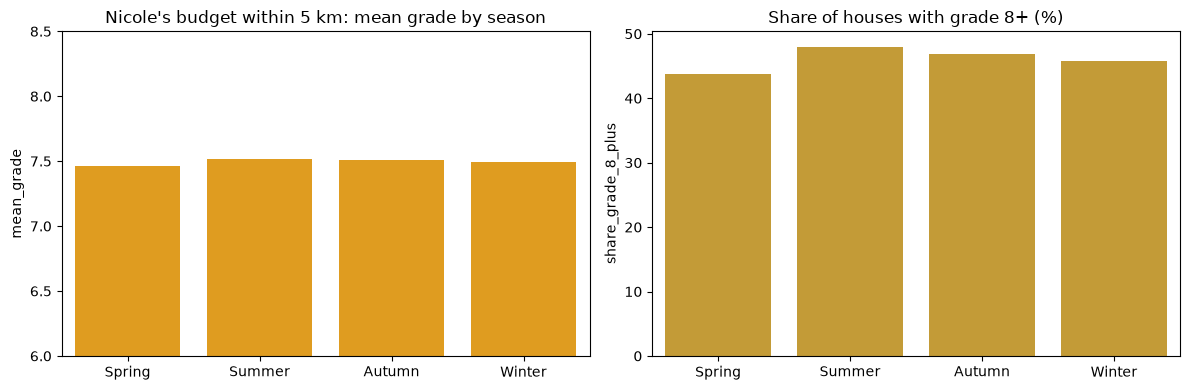

In [204]:
grade_by_season = df_mid.groupby("season").agg(
    mean_grade=("grade", "mean"),
    median_grade=("grade", "median"),
    share_grade_8_plus=("grade", lambda g: (g >= 8).mean() * 100),
    n_sales=("id", "count")).loc[season_order]

grade_by_season.round(2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(x=grade_by_season.index, y=grade_by_season["mean_grade"], color="orange", ax=axes[0])
axes[0].set_ylim(6, 8.5)   # zoom in, since differences will be small
axes[0].set_title(f"Nicole's budget within {max_dist} km: mean grade by season")
axes[0].set_xlabel("")

sns.barplot(x=grade_by_season.index, y=grade_by_season["share_grade_8_plus"], color="goldenrod", ax=axes[1])
axes[1].set_title("Share of houses with grade 8+ (%)")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

**Hypothesis 2 (timing):** Houses sold in winter are cheaper than houses sold in spring and summer, so the buyer gets more for their money by buying in winter.

**Result: partly supported.**

- **County-wide, winter is cheaper.** Across King County, prices per square foot are about 10% lower in December and January (about \$233–235) than at the April peak (about \$260).
- **In the center, there is no clear pattern.** Within 5 km of downtown, prices vary from month to month without a seasonal trend. With only 50–160 sales per month, the differences are most likely due to chance.
- **What Nicole gets for her budget barely changes.** Near the center, her budget buys slightly more space in autumn and winter (about 1,510 sqft) than in spring (about 1,390 sqft), but with few houses this is a weak signal. Build quality is the same in every season (mean grade about 7.5).
- **Winter means less choice.** Far fewer houses sell in winter, both county-wide and in the center.

**Recommendation for Nicole:** Avoid spring, when prices peak county-wide and central houses in her budget are smallest. Beyond that, she shouldn't wait for a particular season. Late summer to autumn offers the best balance: prices below the spring peak, slightly more space, and many more houses to choose from than in winter. Finding the right house in the right location matters more than the month she buys in.

**Limitation:** The data covers only one year (May 2014 to May 2015), so seasonal patterns cannot be confirmed across several years.

Houses within 5 km by construction period:
             median_price  median_ppsf  median_sqft  mean_grade  n_sales
age_group                                                               
Before 1940    707000.000      373.800     2010.000       7.800      735
1940–1969      600000.000      355.800     1930.000       7.500      149
1970–1999      655000.000      356.500     2050.000       8.200      121
2000–2015      530000.000      369.600     1490.000       8.200      343 

Median price per sqft by size (rows) and construction period (columns):
age_group    Before 1940  1940–1969  1970–1999  2000–2015
size_group                                               
< 1,200          446.000    449.000    353.000    393.000
1,200–1,800      391.000    338.000    358.000    348.000
1,800–2,500      353.000    283.000    332.000    347.000
> 2,500          360.000    387.000    361.000    405.000 

Number of houses in each cell (fewer than ~20 = unreliable):
age_group    Before 1940  1940–196

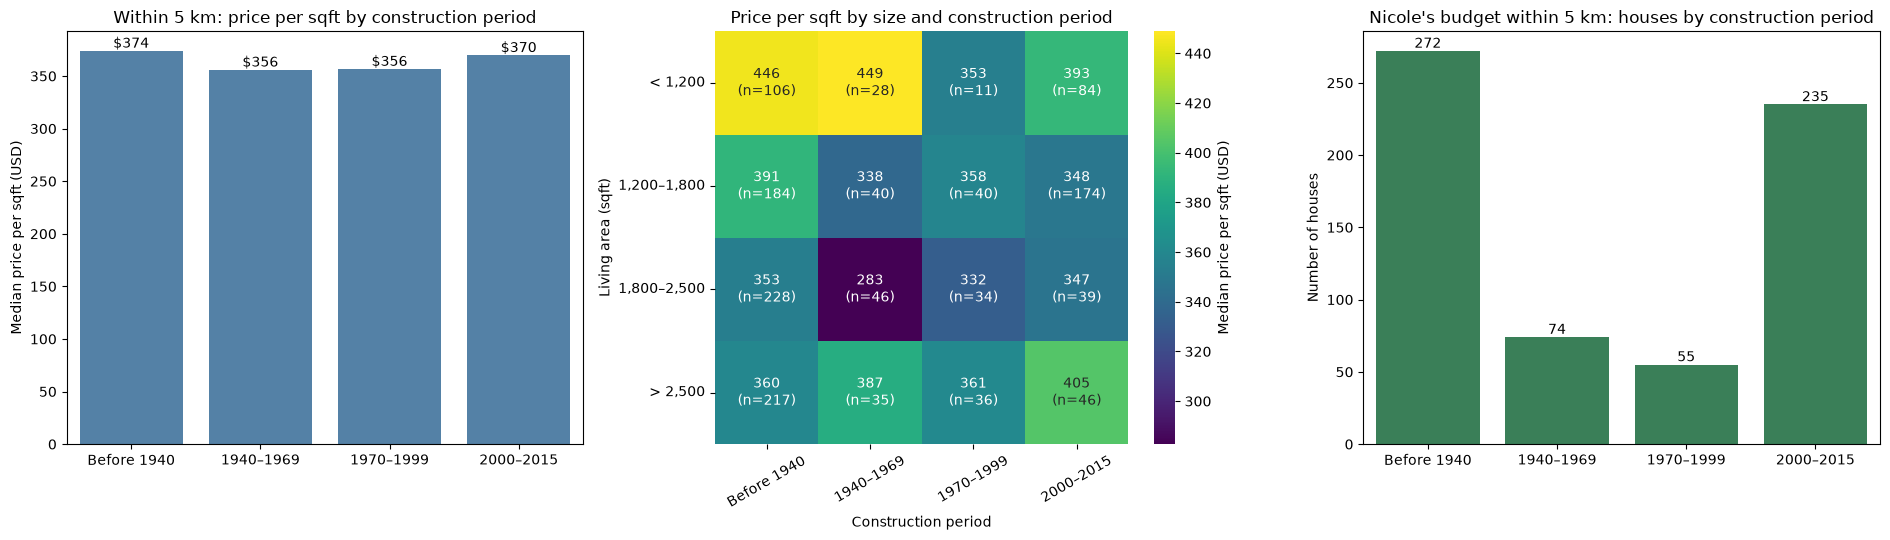

In [207]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- setup ---
downtown_lat, downtown_long = 47.6062, -122.3321
df["dist_km"] = np.sqrt(
    ((df["lat"] - downtown_lat) * 111) ** 2 +
    ((df["long"] - downtown_long) * 111 * np.cos(np.radians(downtown_lat))) ** 2
)
df["price_per_sqft"] = df["price"] / df["sqft_living"]

age_bins = [1899, 1939, 1969, 1999, 2015]
age_labels = ["Before 1940", "1940–1969", "1970–1999", "2000–2015"]
df["age_group"] = pd.cut(df["yr_built"], bins=age_bins, labels=age_labels)

size_bins = [0, 1200, 1800, 2500, 20000]
size_labels = ["< 1,200", "1,200–1,800", "1,800–2,500", "> 2,500"]
df["size_group"] = pd.cut(df["sqft_living"], bins=size_bins, labels=size_labels)

max_dist = 5   # km from downtown
low, high = df["price"].quantile([0.25, 0.75])
df_central = df[df["dist_km"] <= max_dist].copy()
df_mid = df_central[df_central["price"].between(low, high)].copy()

# --- Part 1: are older central houses cheaper? ---
by_age = df_central.groupby("age_group", observed=True).agg(
    median_price=("price", "median"),
    median_ppsf=("price_per_sqft", "median"),
    median_sqft=("sqft_living", "median"),
    mean_grade=("grade", "mean"),
    n_sales=("id", "count"))
print(f"Houses within {max_dist} km by construction period:")
print(by_age.round(1), "\n")

# --- Part 2: same comparison for houses of similar size ---
ppsf_by_size = df_central.pivot_table(index="size_group", columns="age_group",
                                      values="price_per_sqft", aggfunc="median", observed=True)
count_by_size = df_central.pivot_table(index="size_group", columns="age_group",
                                       values="id", aggfunc="count", observed=True)
print("Median price per sqft by size (rows) and construction period (columns):")
print(ppsf_by_size.round(0), "\n")
print("Number of houses in each cell (fewer than ~20 = unreliable):")
print(count_by_size, "\n")

# --- Part 3: what can Nicole find in her budget? ---
mid_by_age = df_mid.groupby("age_group", observed=True).agg(
    median_sqft=("sqft_living", "median"),
    mean_grade=("grade", "mean"),
    mean_condition=("condition", "mean"),
    n_sales=("id", "count"))
mid_by_age["share_%"] = mid_by_age["n_sales"] / mid_by_age["n_sales"].sum() * 100
print(f"Nicole's budget (${low:,.0f}–${high:,.0f}) within {max_dist} km by construction period:")
print(mid_by_age.round(1))

# --- plots ---
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

sns.barplot(x=by_age.index, y=by_age["median_ppsf"], color="steelblue", ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt="$%.0f")
axes[0].set_title(f"Within {max_dist} km: price per sqft by construction period")
axes[0].set_xlabel("")
axes[0].set_ylabel("Median price per sqft (USD)")

# heatmap: price per sqft, with the number of houses below each value
annot = ppsf_by_size.round(0).astype("Int64").astype(str) + "\n(n=" + count_by_size.astype(str) + ")"
sns.heatmap(ppsf_by_size, annot=annot, fmt="", cmap="viridis", ax=axes[1],
            cbar_kws={"label": "Median price per sqft (USD)"})
axes[1].set_title("Price per sqft by size and construction period")
axes[1].set_xlabel("Construction period")
axes[1].set_ylabel("Living area (sqft)")
axes[1].tick_params(axis="y", rotation=0)
axes[1].tick_params(axis="x", rotation=30)

sns.barplot(x=mid_by_age.index, y=mid_by_age["n_sales"], color="seagreen", ax=axes[2])
axes[2].bar_label(axes[2].containers[0])
axes[2].set_title(f"Nicole's budget within {max_dist} km: houses by construction period")
axes[2].set_xlabel("")
axes[2].set_ylabel("Number of houses")

plt.tight_layout()
plt.show()

**Hypothesis 3 (age):** Older houses near the center are cheaper than newer houses of similar size, so the buyer can afford a central home by choosing an older one.

**Result: not supported.**

- Within 5 km of downtown, the oldest houses (built before 1940) have the highest median price per square foot (about \$373), slightly above the newest (2000–2015, about \$369). Houses from 1940–1999 are only about 5% cheaper.
- Comparing houses of similar size shows no consistent age effect: in no size group are the oldest houses the cheapest.
- In Nicole's budget, most central houses are either old (about 270 built before 1940) or new (about 235 built 2000–2015); houses from 1940–1999 are rare.

**Takeaway for Nicole:** Choosing an older house won't save her money in the center. Older and newer central houses cost about the same per square foot, so she can choose based on taste: the character of a pre-1940 house or the modern layout of a newer one.

## Insights

**1. Size and build quality drive house prices.**
Across all houses, price is most strongly related to grade (Spearman correlation 0.66) and living area (0.64), followed by the living area of the neighbors (0.57) and the number of bathrooms (0.50). Many of these variables measure the same thing, since bigger houses tend to have more bathrooms and a higher grade. Condition (0.02), lot size (0.08) and year built (0.10) show almost no relationship with price.

**2. Location matters: the closer to downtown and the further north, the more expensive (geographical insight).**
The median price per square foot falls steadily with distance to downtown Seattle, from about \$370 within 5 km to about \$170 at 30–50 km. Latitude is also clearly related to price (0.46), while longitude is not (0.06): northern areas are more expensive than southern ones. Even within 5 km of downtown, the northern zip codes (98119 Queen Anne, 98109, 98102, 98112) are the most expensive per square foot, while 98122 (Central District) and 98144 (Beacon Hill, Mount Baker) are cheaper and have the most sales.

**3. Prices and sales follow a seasonal pattern across the county.**
County-wide, prices per square foot peak in April (about \$260) and are lowest in December and January (about \$233–235), around 10% lower. Sales follow the same rhythm: about 2,400 in May, compared with fewer than 1,000 in January. Near the center, however, the pattern is not clear, as there are too few sales per month.

**4. House age has little effect on price.**
Year built is barely related to price, because two effects cancel each other out: newer houses are bigger and better built, but older houses are more often in expensive central locations. Within 5 km of downtown, the oldest houses (before 1940) even have a slightly higher price per square foot than houses built between 1940 and 1999.

## Recommendations for Nicole Johnson

**1. Focus on 98122 (Central District) and 98144 (Beacon Hill, Mount Baker).**
Both are only 2–3 km from downtown, offer the most houses in her budget (\$322,000–\$645,000) and have a lower price per square foot than the northern central neighborhoods. 98122 borders Capitol Hill, one of Seattle's liveliest areas.

**2. Expect a smaller house in exchange for a central location, without giving up quality.**
Within 10 km of downtown, a typical house in her budget has about 1,470 sqft, compared with about 2,400 sqft at 30–50 km. Build quality is the same at every distance (mostly grade 7–8). If she needs more space, every extra 10 km from downtown buys noticeably more room.

**3. Avoid buying in spring, and aim for late summer to autumn.**
Spring (especially March–April) is the most expensive time county-wide, and central houses in her budget are smallest then. Late summer to autumn offers a good balance of prices below the spring peak and plenty of houses to choose from. Winter is cheaper county-wide but offers far less choice.

**4. Choose between older and newer houses based on taste, not price.**
Older central houses are not cheaper than newer ones of similar size. Most of her central options are either built before 1940 or after 2000, so she can choose between the character of an older house and the modern layout of a newer one without a price difference.

## Limitations

- The data covers only one year (May 2014 to May 2015), so seasonal patterns cannot be confirmed across several years.
- "Lively" is not measured directly; it is approximated by central location and the number of sales.
- Some central subgroups contain few houses, so small differences between them may be due to chance.